<a href="https://colab.research.google.com/github/cesr1971/MLPYTHON/blob/main/MLPYTHON_TRAB01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Trabalho de Machine learning e Python**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('train.csv', encoding='utf-8')
# Carregar o arquivo de treino


In [3]:
df.info()
# Conhecer a estrutura do DF

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20758 entries, 0 to 20757
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              20758 non-null  int64  
 1   Gender                          20758 non-null  object 
 2   Age                             20758 non-null  float64
 3   Height                          20758 non-null  float64
 4   Weight                          20758 non-null  float64
 5   family_history_with_overweight  20758 non-null  object 
 6   FAVC                            20758 non-null  object 
 7   FCVC                            20758 non-null  float64
 8   NCP                             20758 non-null  float64
 9   CAEC                            20758 non-null  object 
 10  SMOKE                           20758 non-null  object 
 11  CH2O                            20758 non-null  float64
 12  SCC                             

In [4]:
# Conhecer as Dimensões da base
print(f"\nTotal (linhas): {df.shape[0]}")
print(f"Total (colunas): {df.shape[1]}")


Total (linhas): 20758
Total (colunas): 18


In [5]:
df1 = pd.read_csv('test.csv', encoding='utf-8')

In [6]:
df1.info()
# Conhecer a estrutura do DF teste

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13840 entries, 0 to 13839
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              13840 non-null  int64  
 1   Gender                          13840 non-null  object 
 2   Age                             13840 non-null  float64
 3   Height                          13840 non-null  float64
 4   Weight                          13840 non-null  float64
 5   family_history_with_overweight  13840 non-null  object 
 6   FAVC                            13840 non-null  object 
 7   FCVC                            13840 non-null  float64
 8   NCP                             13840 non-null  float64
 9   CAEC                            13840 non-null  object 
 10  SMOKE                           13840 non-null  object 
 11  CH2O                            13840 non-null  float64
 12  SCC                             

In [7]:
# Conhecer as Dimensões da base
print(f"\nTotal (linhas): {df1.shape[0]}")
print(f"Total (colunas): {df1.shape[1]}")


Total (linhas): 13840
Total (colunas): 17


**Vamos criar uma coluna como sugestão em Aula.**

In [8]:
# Criar a coluna IMC (considerando height em centímetros e weight em kg)
df["IMC"] = df["Weight"] / (df["Height"] / 100) ** 2

# Arredondar o IMC para duas casas decimais
df["IMC"] = df["IMC"].round(2)



In [9]:
# Variável alvo: aquilo que queremos prever
alvo = 'NObeyesdad'

# Removemos a coluna id porque ela é apenas um identificador
X = df.drop(columns=[alvo, 'id'])

# y contém as categorias que o modelo deverá aprender
y = df[alvo]


In [10]:
# Criar a coluna IMC (considerando height em centímetros e weight em kg)
df1["IMC"] = df1["Weight"] / (df1["Height"] / 100) ** 2

# Arredondar o IMC para duas casas decimais
df1["IMC"] = df1["IMC"].round(2)



In [11]:
display(df)

,id,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad,IMC
0,0,Male,24.443011,1.699998,81.669950,yes,yes,2.000000,2.983297,Sometimes,no,2.763573,no,0.000000,0.976473,Sometimes,Public_Transportation,Overweight_Level_II,282595.65
1,1,Female,18.000000,1.560000,57.000000,yes,yes,2.000000,3.000000,Frequently,no,2.000000,no,1.000000,1.000000,no,Automobile,Normal_Weight,234220.91
2,2,Female,18.000000,1.711460,50.165754,yes,yes,1.880534,1.411685,Sometimes,no,1.910378,no,0.866045,1.673584,no,Public_Transportation,Insufficient_Weight,171267.06
3,3,Female,20.952737,1.710730,131.274851,yes,yes,3.000000,3.000000,Sometimes,no,1.674061,no,1.467863,0.780199,Sometimes,Public_Transportation,Obesity_Type_III,448557.98
4,4,Male,31.641081,1.914186,93.798055,yes,yes,2.679664,1.971472,Sometimes,no,1.979848,no,1.967973,0.931721,Sometimes,Public_Transportation,Overweight_Level_II,255991.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20753,20753,Male,25.137087,1.766626,114.187096,yes,yes,2.919584,3.000000,Sometimes,no,2.151809,no,1.330519,0.196680,Sometimes,Public_Transportation,Obesity_Type_II,365870.84
20754,20754,Male,18.000000,1.710000,50.000000,no,yes,3.000000,4.000000,Frequently,no,1.000000,no,2.000000,1.000000,Sometimes,Public_Transportation,Insufficient_Weight,170992.78
20755,20755,Male,20.101026,1.819557,105.580491,yes,yes,2.407817,3.000000,Sometimes,no,2.000000,no,1.158040,1.198439,no,Public_Transportation,Obesity_Type_II,318898.41
20756,20756,Male,33.852953,1.700000,83.520113,yes,yes,2.671238,1.971472,Sometimes,no,2.144838,no,0.000000,0.973834,no,Automobile,Overweight_Level_II,288996.93


In [12]:
df.describe()
# Estatísticas gerais das colunas numéricas

,id,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE,IMC
count,20758.00000,20758.000000,20758.000000,20758.000000,20758.000000,20758.000000,20758.000000,20758.000000,20758.000000,20758.000000
mean,10378.50000,23.841804,1.700245,87.887768,2.445908,2.761332,2.029418,0.981747,0.616756,302418.416886
std,5992.46278,5.688072,0.087312,26.379443,0.533218,0.705375,0.608467,0.838302,0.602113,83339.319050
min,0.00000,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000,128685.410000
25%,5189.25000,20.000000,1.631856,66.000000,2.000000,3.000000,1.792022,0.008013,0.000000,240882.230000
50%,10378.50000,22.815416,1.700000,84.064875,2.393837,3.000000,2.000000,1.000000,0.573887,293847.570000
75%,15567.75000,26.000000,1.762887,111.600553,3.000000,3.000000,2.549617,1.587406,1.000000,370111.677500
max,20757.00000,61.000000,1.975663,165.057269,3.000000,4.000000,3.000000,3.000000,2.000000,549979.910000


In [13]:
df['CALC'].unique() # Indica Realiza consumo de alcool Frequentemente na base (Valor distinto).

array(['Sometimes', 'no', 'Frequently'], dtype=object)

In [14]:
df['MTRANS'].unique() # Indica Modo de Transporte (Valor Distinto).

array(['Public_Transportation', 'Automobile', 'Walking', 'Motorbike',
       'Bike'], dtype=object)

In [15]:
df['NObeyesdad'].unique() # Indica Nivel de Obesidade (Valor Distinto).

array(['Overweight_Level_II', 'Normal_Weight', 'Insufficient_Weight',
       'Obesity_Type_III', 'Obesity_Type_II', 'Overweight_Level_I',
       'Obesity_Type_I'], dtype=object)

In [16]:
df['SMOKE'].unique() # Indica se a pessoa é fumante (Valor Distinto).

array(['no', 'yes'], dtype=object)

In [17]:
df['CAEC'].unique() # Indica frequencia de alimentos entre as refeições (Valor Distinto).

array(['Sometimes', 'Frequently', 'no', 'Always'], dtype=object)

In [18]:
df['FAVC'].unique() # Indica se faz consumo de comida calorica (Valor Distinto).

array(['yes', 'no'], dtype=object)

In [19]:
df['family_history_with_overweight'].unique() # Indica se possui historico de Obesidade na Familia (Valor Distinto).

array(['yes', 'no'], dtype=object)

**Vamos iniciar a geração dos graficos para entender esta base de dados.**

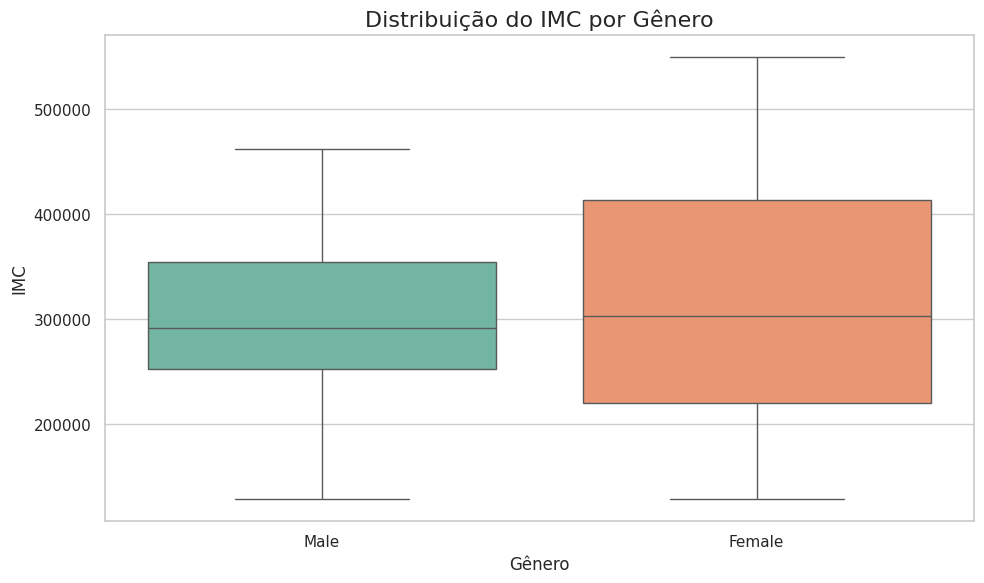

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo
sns.set_theme(style="whitegrid")

# Criar o gráfico
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Gender",
    y="IMC",
    hue="Gender",
    palette="Set2",
    legend=False
)

# Personalizar o gráfico
plt.title("Distribuição do IMC por Gênero", fontsize=16)
plt.xlabel("Gênero", fontsize=12)
plt.ylabel("IMC", fontsize=12)

plt.tight_layout()
plt.show()

Entendo o Grafico acima fica claro a dizer que os homes possuem um IMC para concentrado diante da Base apresentada, já as mulhees os valores médios são mais espassados.

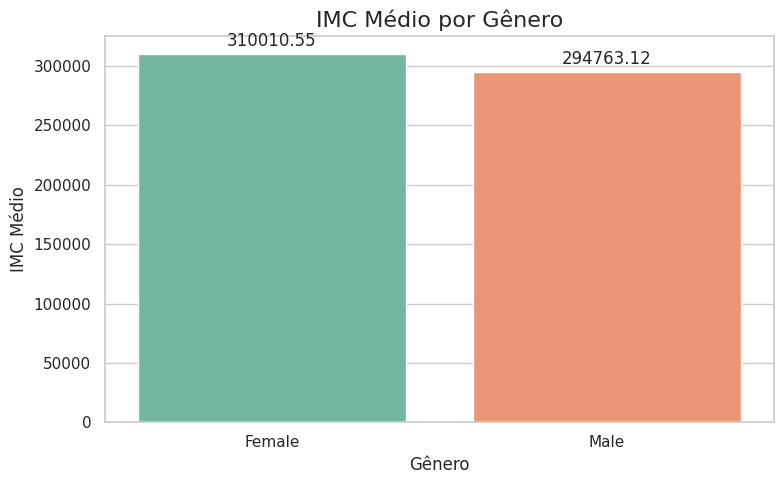

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular o IMC médio por gênero
imc_medio = df.groupby("Gender", as_index=False)["IMC"].mean()

# Criar o gráfico
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=imc_medio,
    x="Gender",
    y="IMC",
    hue="Gender",
    palette="Set2",
    legend=False
)

# Exibir os valores sobre as barras
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("IMC Médio por Gênero", fontsize=16)
plt.xlabel("Gênero")
plt.ylabel("IMC Médio")
plt.tight_layout()
plt.show()

**Distribuição dos níveis de obesidade por gênero.**

Permite visualizar como os níveis de obesidade estão distribuídos entre homens e mulheres, identificando a quantidade de registros em cada categoria de obesidade para cada gênero.

<Figure size 1200x600 with 0 Axes>

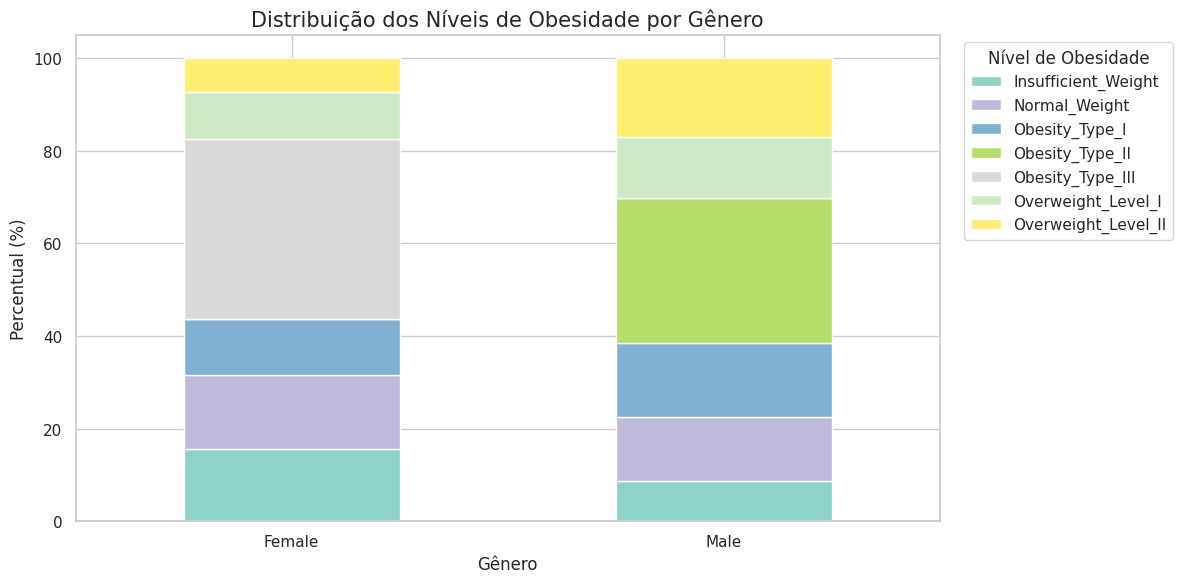

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6))

# Calcular a proporção dos níveis de obesidade por gênero
dados = pd.crosstab(
    df["Gender"],
    df["NObeyesdad"],
    normalize="index"
) * 100

dados.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="Set3"
)

plt.title("Distribuição dos Níveis de Obesidade por Gênero", fontsize=15)
plt.xlabel("Gênero")
plt.ylabel("Percentual (%)")
plt.xticks(rotation=0)
plt.legend(title="Nível de Obesidade", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

**Relação entre idade e peso por nível de obesidade**

O gráfico de dispersão permite observar como o peso varia conforme a idade e identificar a concentração de registros de cada nível de obesidade. As cores representam as categorias da variável NObeyesdad.
Ele também pode ajudar a identificar agrupamentos e possíveis valores discrepantes.

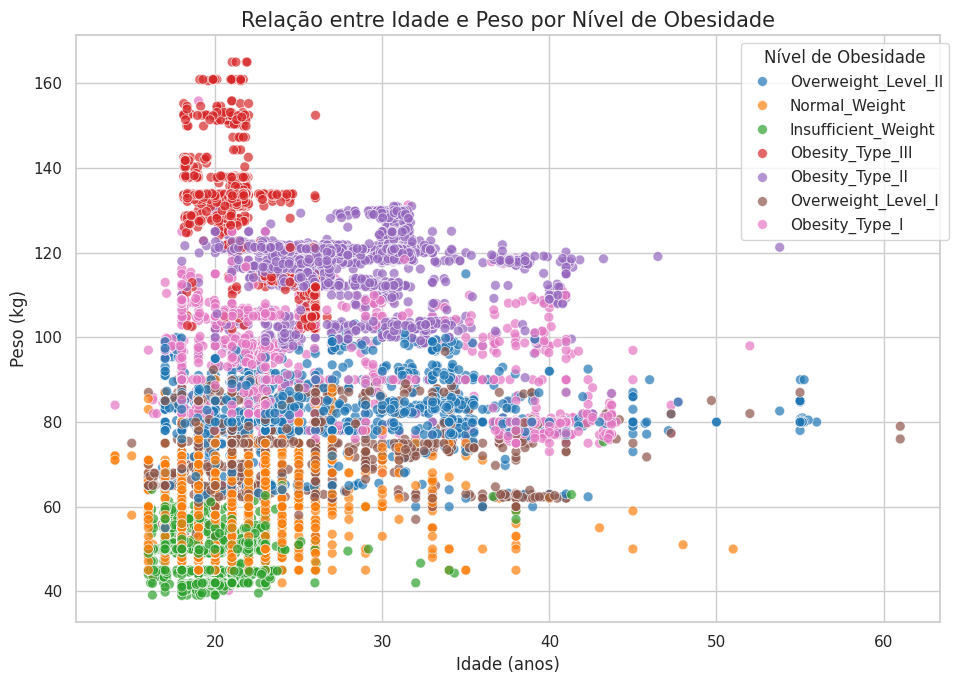

In [23]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="Age",
    y="Weight",
    hue="NObeyesdad",
    alpha=0.7,
    palette="tab10",
    s=50
)

plt.title("Relação entre Idade e Peso por Nível de Obesidade", fontsize=15)
plt.xlabel("Idade (anos)")
plt.ylabel("Peso (kg)")
plt.legend(title="Nível de Obesidade", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

**Histórico familiar de sobrepeso e nível de obesidade**

Este gráfico permite comparar a distribuição dos níveis de obesidade entre pessoas que possuem e que não possuem histórico familiar de sobrepeso (family_history_with_overweight).
A visualização em percentual facilita identificar diferenças na composição das categorias de obesidade entre os dois grupos, sendo útil para investigar a associação entre histórico familiar e nível de obesidade.

<Figure size 1200x700 with 0 Axes>

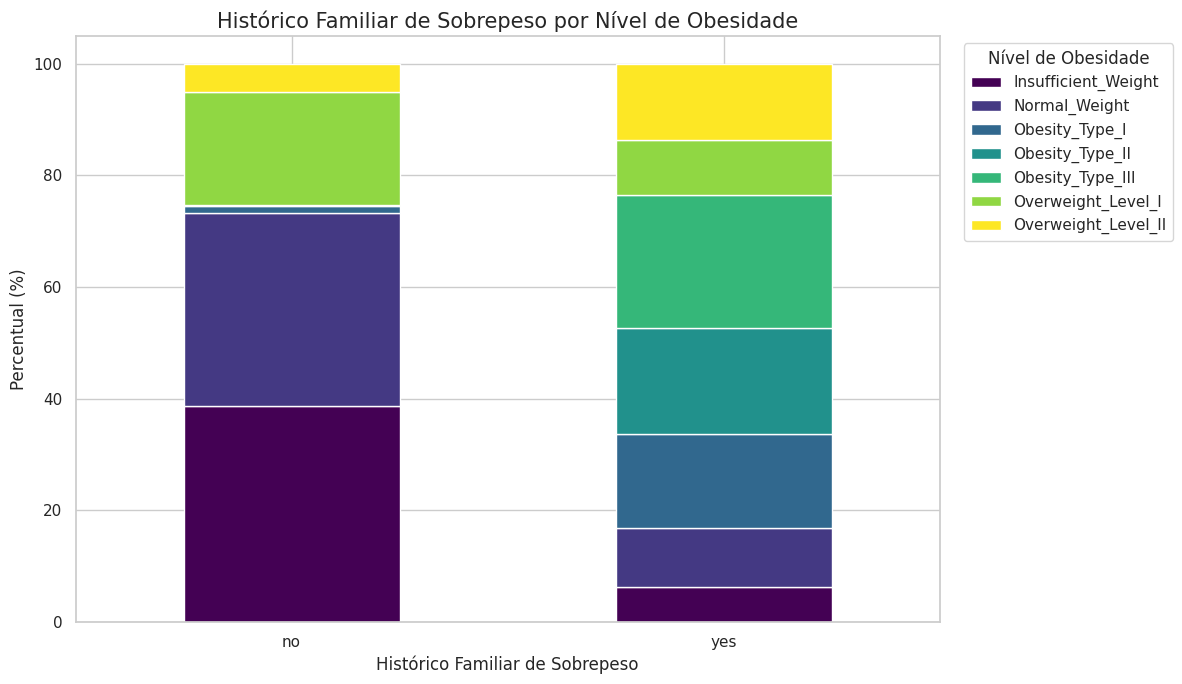

In [24]:
plt.figure(figsize=(12, 7))

dados_familia = pd.crosstab(
    df["family_history_with_overweight"],
    df["NObeyesdad"],
    normalize="index"
) * 100

dados_familia.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 7),
    colormap="viridis"
)

plt.title("Histórico Familiar de Sobrepeso por Nível de Obesidade", fontsize=15)
plt.xlabel("Histórico Familiar de Sobrepeso")
plt.ylabel("Percentual (%)")
plt.xticks(rotation=0)
plt.legend(title="Nível de Obesidade", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

**Criando Heatmap com a correlação dos principais indicadores**

**Identificar colunas numéricas e categóricas**

In [25]:
colunas_numericas = [
    'Age',
    'Height',
    'Weight',
    'FCVC',
    'NCP',
    'CH2O',
    'FAF',
    'TUE'
]

colunas_categoricas = [
    'Gender',
    'family_history_with_overweight',
    'FAVC',
    'CAEC',
    'SMOKE',
    'SCC',
    'CALC',
    'MTRANS'
]


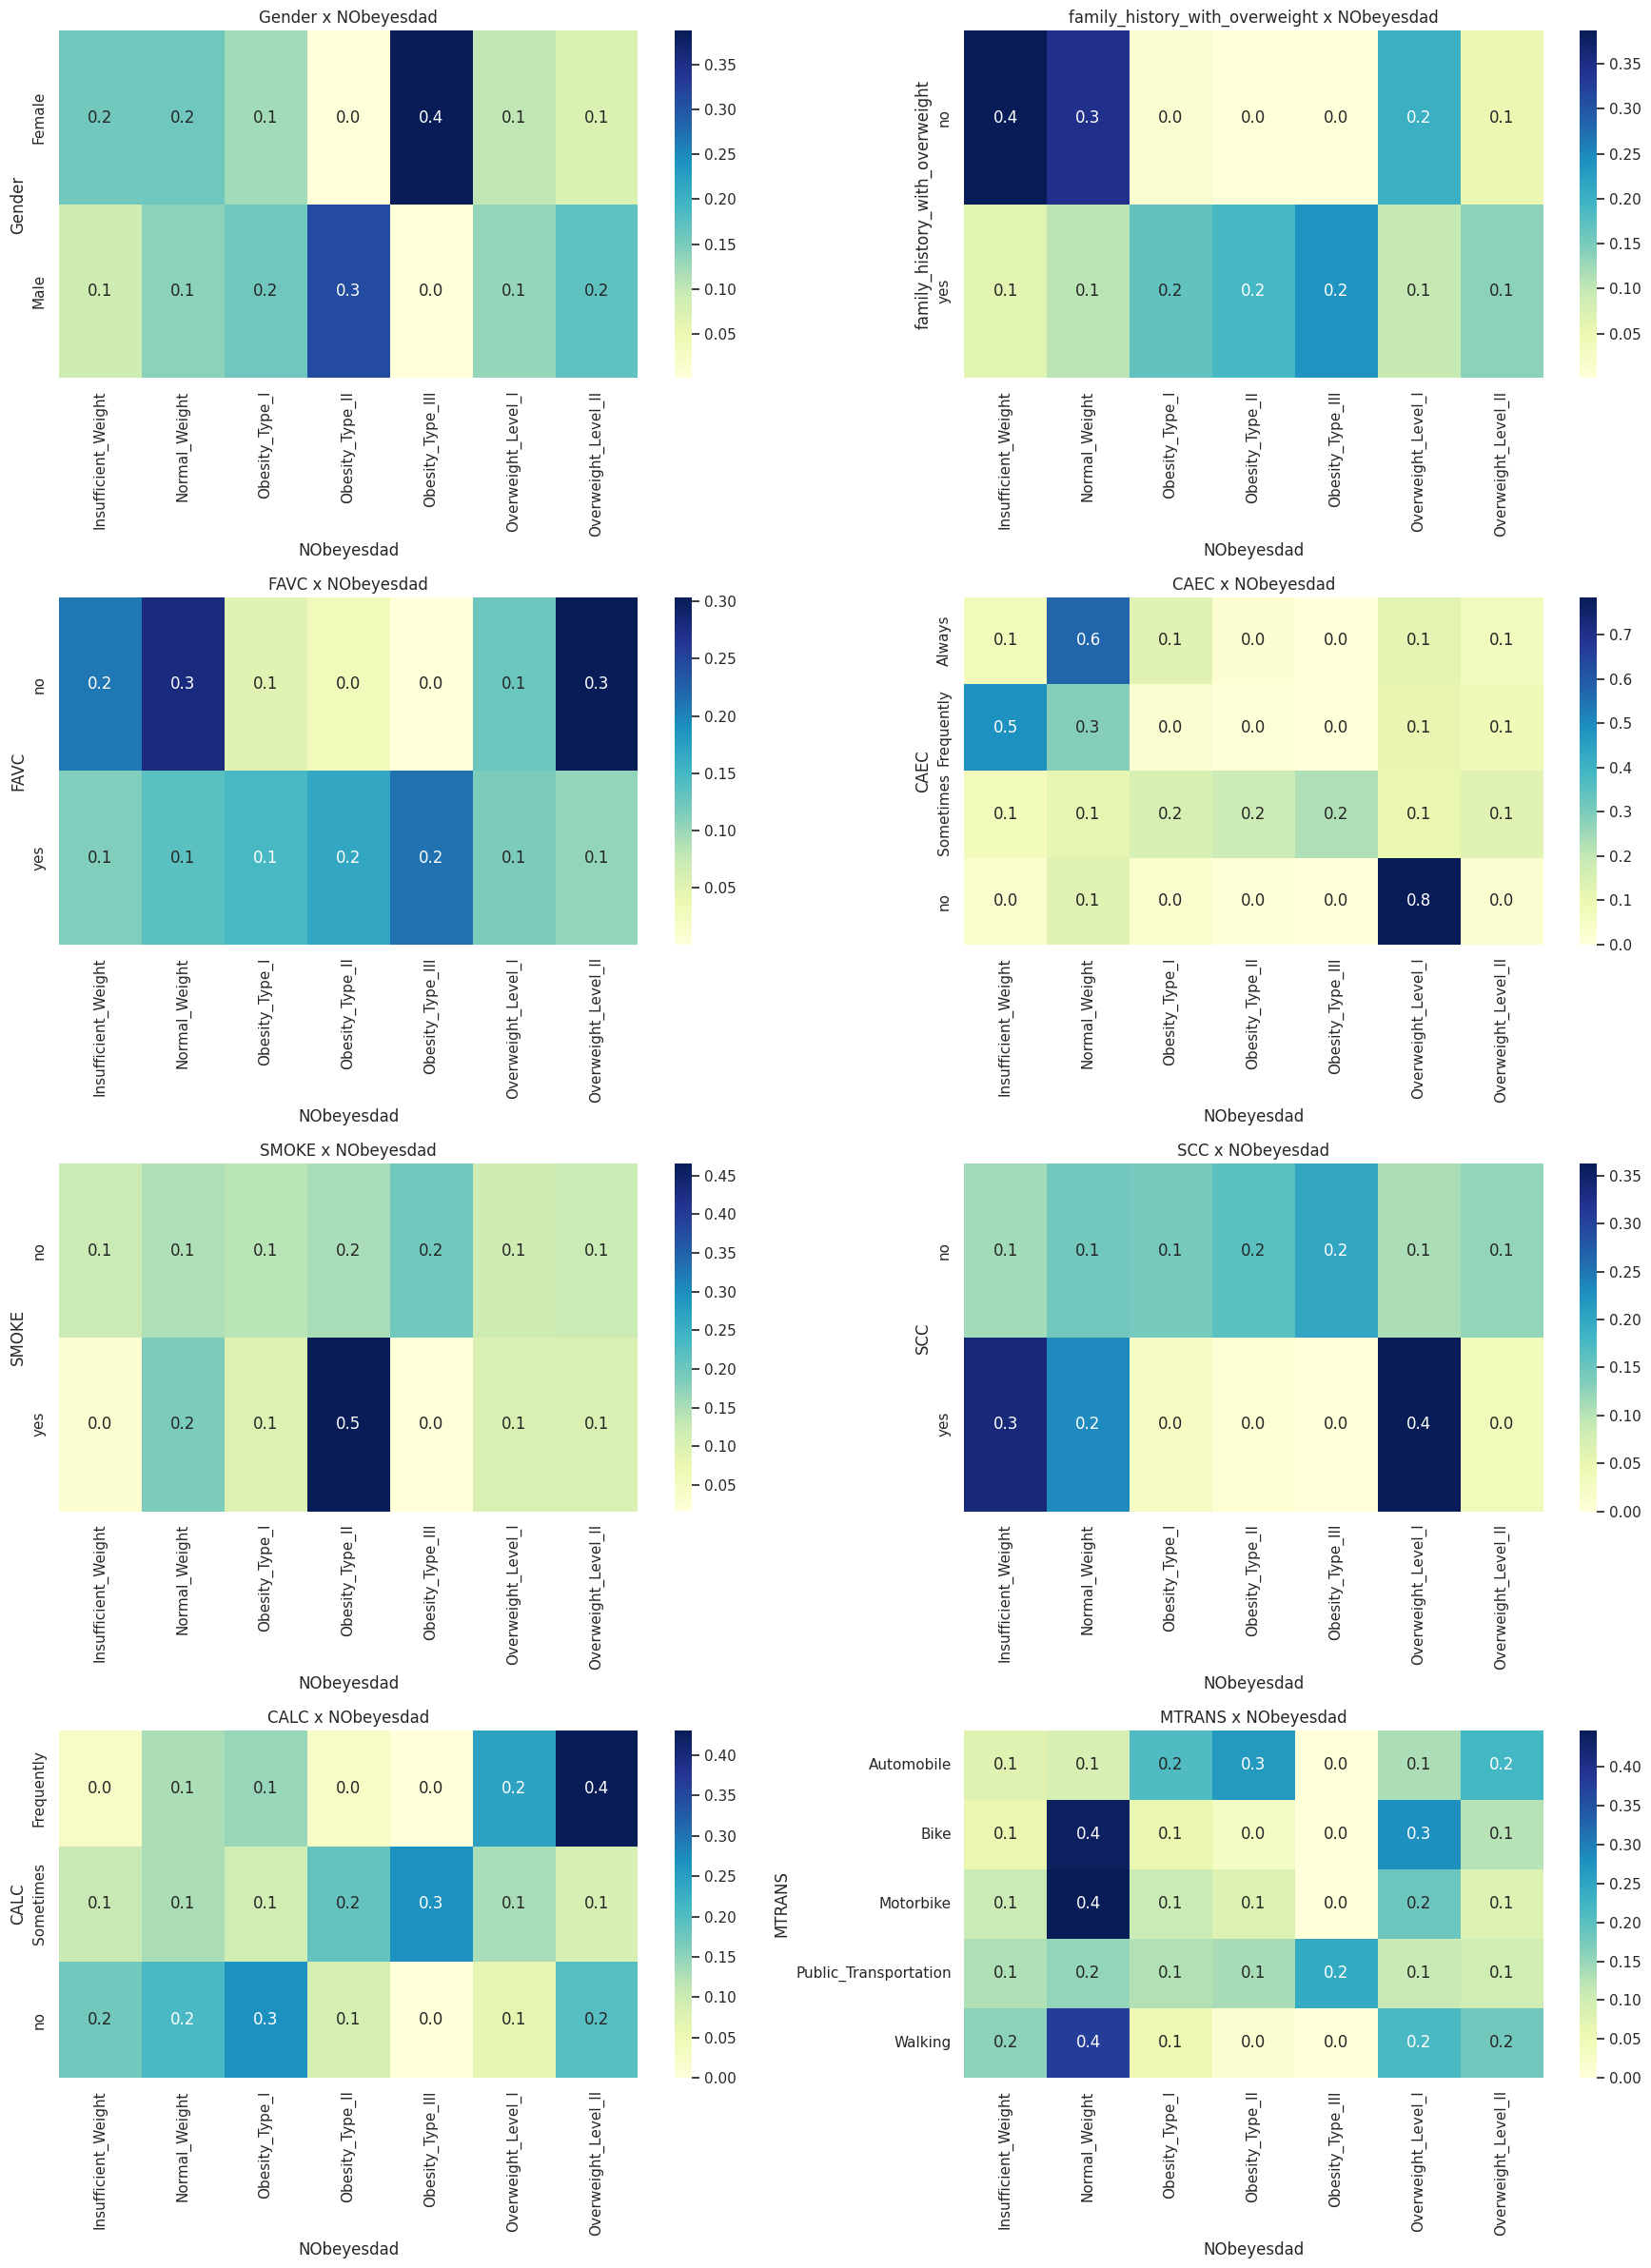

In [26]:
fig, axes = plt.subplots(
    4, 2,
    figsize=(18, 24)
)

axes = axes.flatten()

for i, coluna in enumerate(colunas_categoricas):

    tabela = pd.crosstab(
        df[coluna],
        df['NObeyesdad'],
        normalize='index'
    )

    sns.heatmap(
        tabela,
        annot=True,
        fmt='.1f',
        cmap='YlGnBu',
        ax=axes[i]
    )

    axes[i].set_title(f'{coluna} x NObeyesdad')
    axes[i].set_xlabel('NObeyesdad')
    axes[i].set_ylabel(coluna)

plt.tight_layout()
plt.show()


**Distribuição das categorias de obesidade**

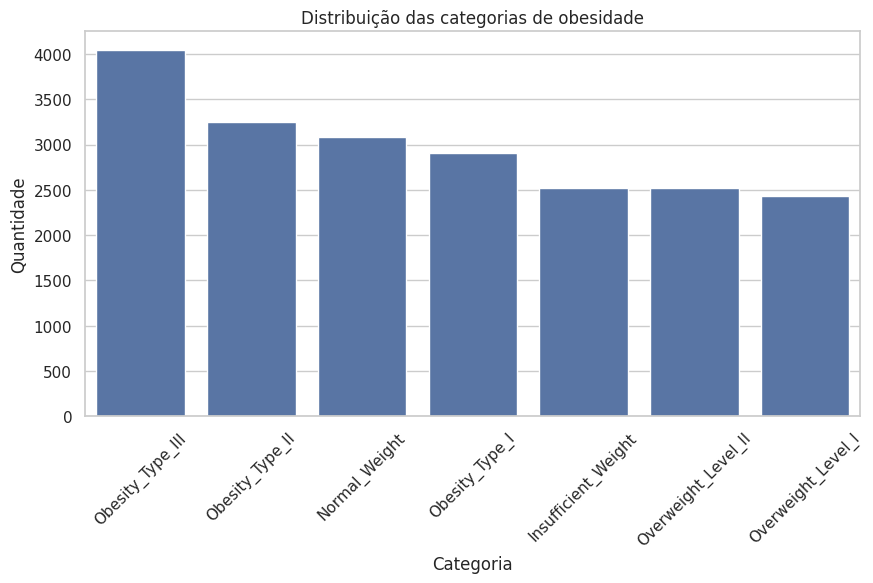

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='NObeyesdad',
    order=df['NObeyesdad'].value_counts().index
)

plt.xticks(rotation=45)
plt.title('Distribuição das categorias de obesidade')
plt.xlabel('Categoria')
plt.ylabel('Quantidade')
plt.show()


**Criar Variavel Alvo**

In [27]:
# Variável alvo: aquilo que queremos prever
alvo = 'NObeyesdad'

# Removemos a coluna id porque ela é apenas um identificador
X = df.drop(columns=[alvo, 'id'])

# y contém as categorias que o modelo deverá aprender
y = df[alvo]

**Verificando as categorias do alvo**

In [28]:
print(y.unique())
print(y.value_counts())

['Overweight_Level_II' 'Normal_Weight' 'Insufficient_Weight'
 'Obesity_Type_III' 'Obesity_Type_II' 'Overweight_Level_I'
 'Obesity_Type_I']
NObeyesdad
Obesity_Type_III       4046
Obesity_Type_II        3248
Normal_Weight          3082
Obesity_Type_I         2910
Insufficient_Weight    2523
Overweight_Level_II    2522
Overweight_Level_I     2427
Name: count, dtype: int64


**Separando dados de treinamento e teste**


80% dos dados para treinamento;

20% dos dados para teste.

O que significa stratify=y?

Ele garante que a proporção das categorias seja aproximadamente preservada nos conjuntos de treinamento e teste.
Por exemplo, se uma categoria representa 20% dos dados originais, ela continuará representando aproximadamente 20% tanto no treinamento quanto no teste.

In [30]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


**Criando o pré-processamento**

In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessamento = ColumnTransformer(
    transformers=[
        (
            'categoricas',
            OneHotEncoder(handle_unknown='ignore'),
            colunas_categoricas
        ),
        (
            'numericas',
            'passthrough',
            colunas_numericas
        )
    ]
)


**Criar a árvore de decisão**

Significado dos parâmetros

criterion='entropy': critério usado para escolher as melhores divisões;

max_depth=5: limita a profundidade da árvore;

min_samples_split=10: uma divisão só será feita se houver pelo menos 10 exemplos;

min_samples_leaf=5: cada folha precisa ter pelo menos 5 exemplos;

random_state=42: permite reproduzir o resultado.

In [32]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

arvore = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)


**Juntando o pré-processamento e o modelo**

In [33]:
modelo = Pipeline(
    steps=[
        ('preprocessamento', preprocessamento),
        ('arvore', arvore)
    ]
)


**Treino do Modelo**

In [34]:
modelo.fit(X_treino, y_treino)


Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('categoricas',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender',
                                                   'family_history_with_overweight',
                                                   'FAVC', 'CAEC', 'SMOKE',
                                                   'SCC', 'CALC', 'MTRANS']),
                                                 ('numericas', 'passthrough',
                                                  ['Age', 'Height', 'Weight',
                                                   'FCVC', 'NCP', 'CH2O', 'FAF',
                                                   'TUE'])])),
                ('arvore',
                 DecisionTreeClassifier(criterion='entropy', max_depth=5,
                                        min_samples_leaf=5,
                                        min_samples_split=10,
                                        random_state=42))])

**Realizando as Previsões**

y_teste contém os valores reais;

y_pred contém as previsões feitas pelo modelo.

In [35]:
y_pred = modelo.predict(X_teste)


In [36]:
comparacao = pd.DataFrame({
    'Real': y_teste.values,
    'Previsto': y_pred
})

comparacao.head(10)


,Real,Previsto
0,Normal_Weight,Normal_Weight
1,Normal_Weight,Normal_Weight
2,Obesity_Type_II,Obesity_Type_II
3,Obesity_Type_III,Obesity_Type_III
4,Obesity_Type_I,Obesity_Type_I
5,Obesity_Type_III,Obesity_Type_III
6,Obesity_Type_I,Obesity_Type_I
7,Overweight_Level_II,Obesity_Type_I
8,Obesity_Type_I,Obesity_Type_I
9,Normal_Weight,Overweight_Level_I


**Criando Heatmap com a correlação dos principais indicadores**

**Criando Pairplot Elegiveis a Obesidade**


Elegível para obesidade: categorias Obesity_Type_I, Obesity_Type_II ou Obesity_Type_III;

Não elegível para obesidade: Insufficient_Weight, Normal_Weight e Overweight_Level_I/II.

In [37]:
# Vou criar minhas variaveis
categorias_obesidade = [
    'Obesity_Type_I',
    'Obesity_Type_II',
    'Obesity_Type_III'
]

df['Elegivel_Obesidade'] = df['NObeyesdad'].isin(
    categorias_obesidade
)

df['Elegivel_Obesidade'] = df['Elegivel_Obesidade'].map({
    True: 'Elegível',
    False: 'Não elegível'
})


/tmp/ipykernel_1257/472007553.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


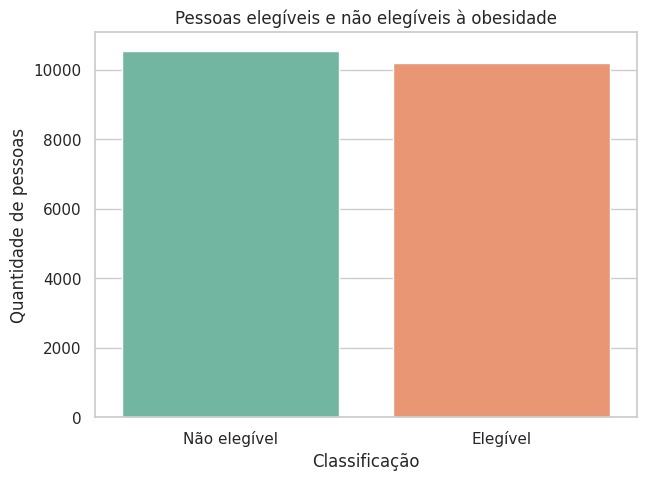

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Elegivel_Obesidade',
    order=['Não elegível', 'Elegível'],
    palette='Set2'
)

plt.title('Pessoas elegíveis e não elegíveis à obesidade')
plt.xlabel('Classificação')
plt.ylabel('Quantidade de pessoas')
plt.show()


In [39]:
features_numericas1 = [
    'Age',
    'Height',
    'Weight',
    'FCVC',
    'NCP',
    'CH2O',
    'FAF',
    'TUE'
]


Como interpretar o grafico abaixo:

Cada ponto representa uma pessoa.

As cores representam:

verde: pessoa não elegível;
vermelho: pessoa elegível.

Cada gráfico compara duas variáveis. Por exemplo:
Weight x Age;
Weight x FAF;
Height x Weight.

Se os pontos vermelhos e verdes formarem grupos bem separados, isso indica que aquela combinação de variáveis pode ajudar a distinguir os grupos.

Se houver muita sobreposição, significa que as variáveis analisadas não separam claramente as pessoas.

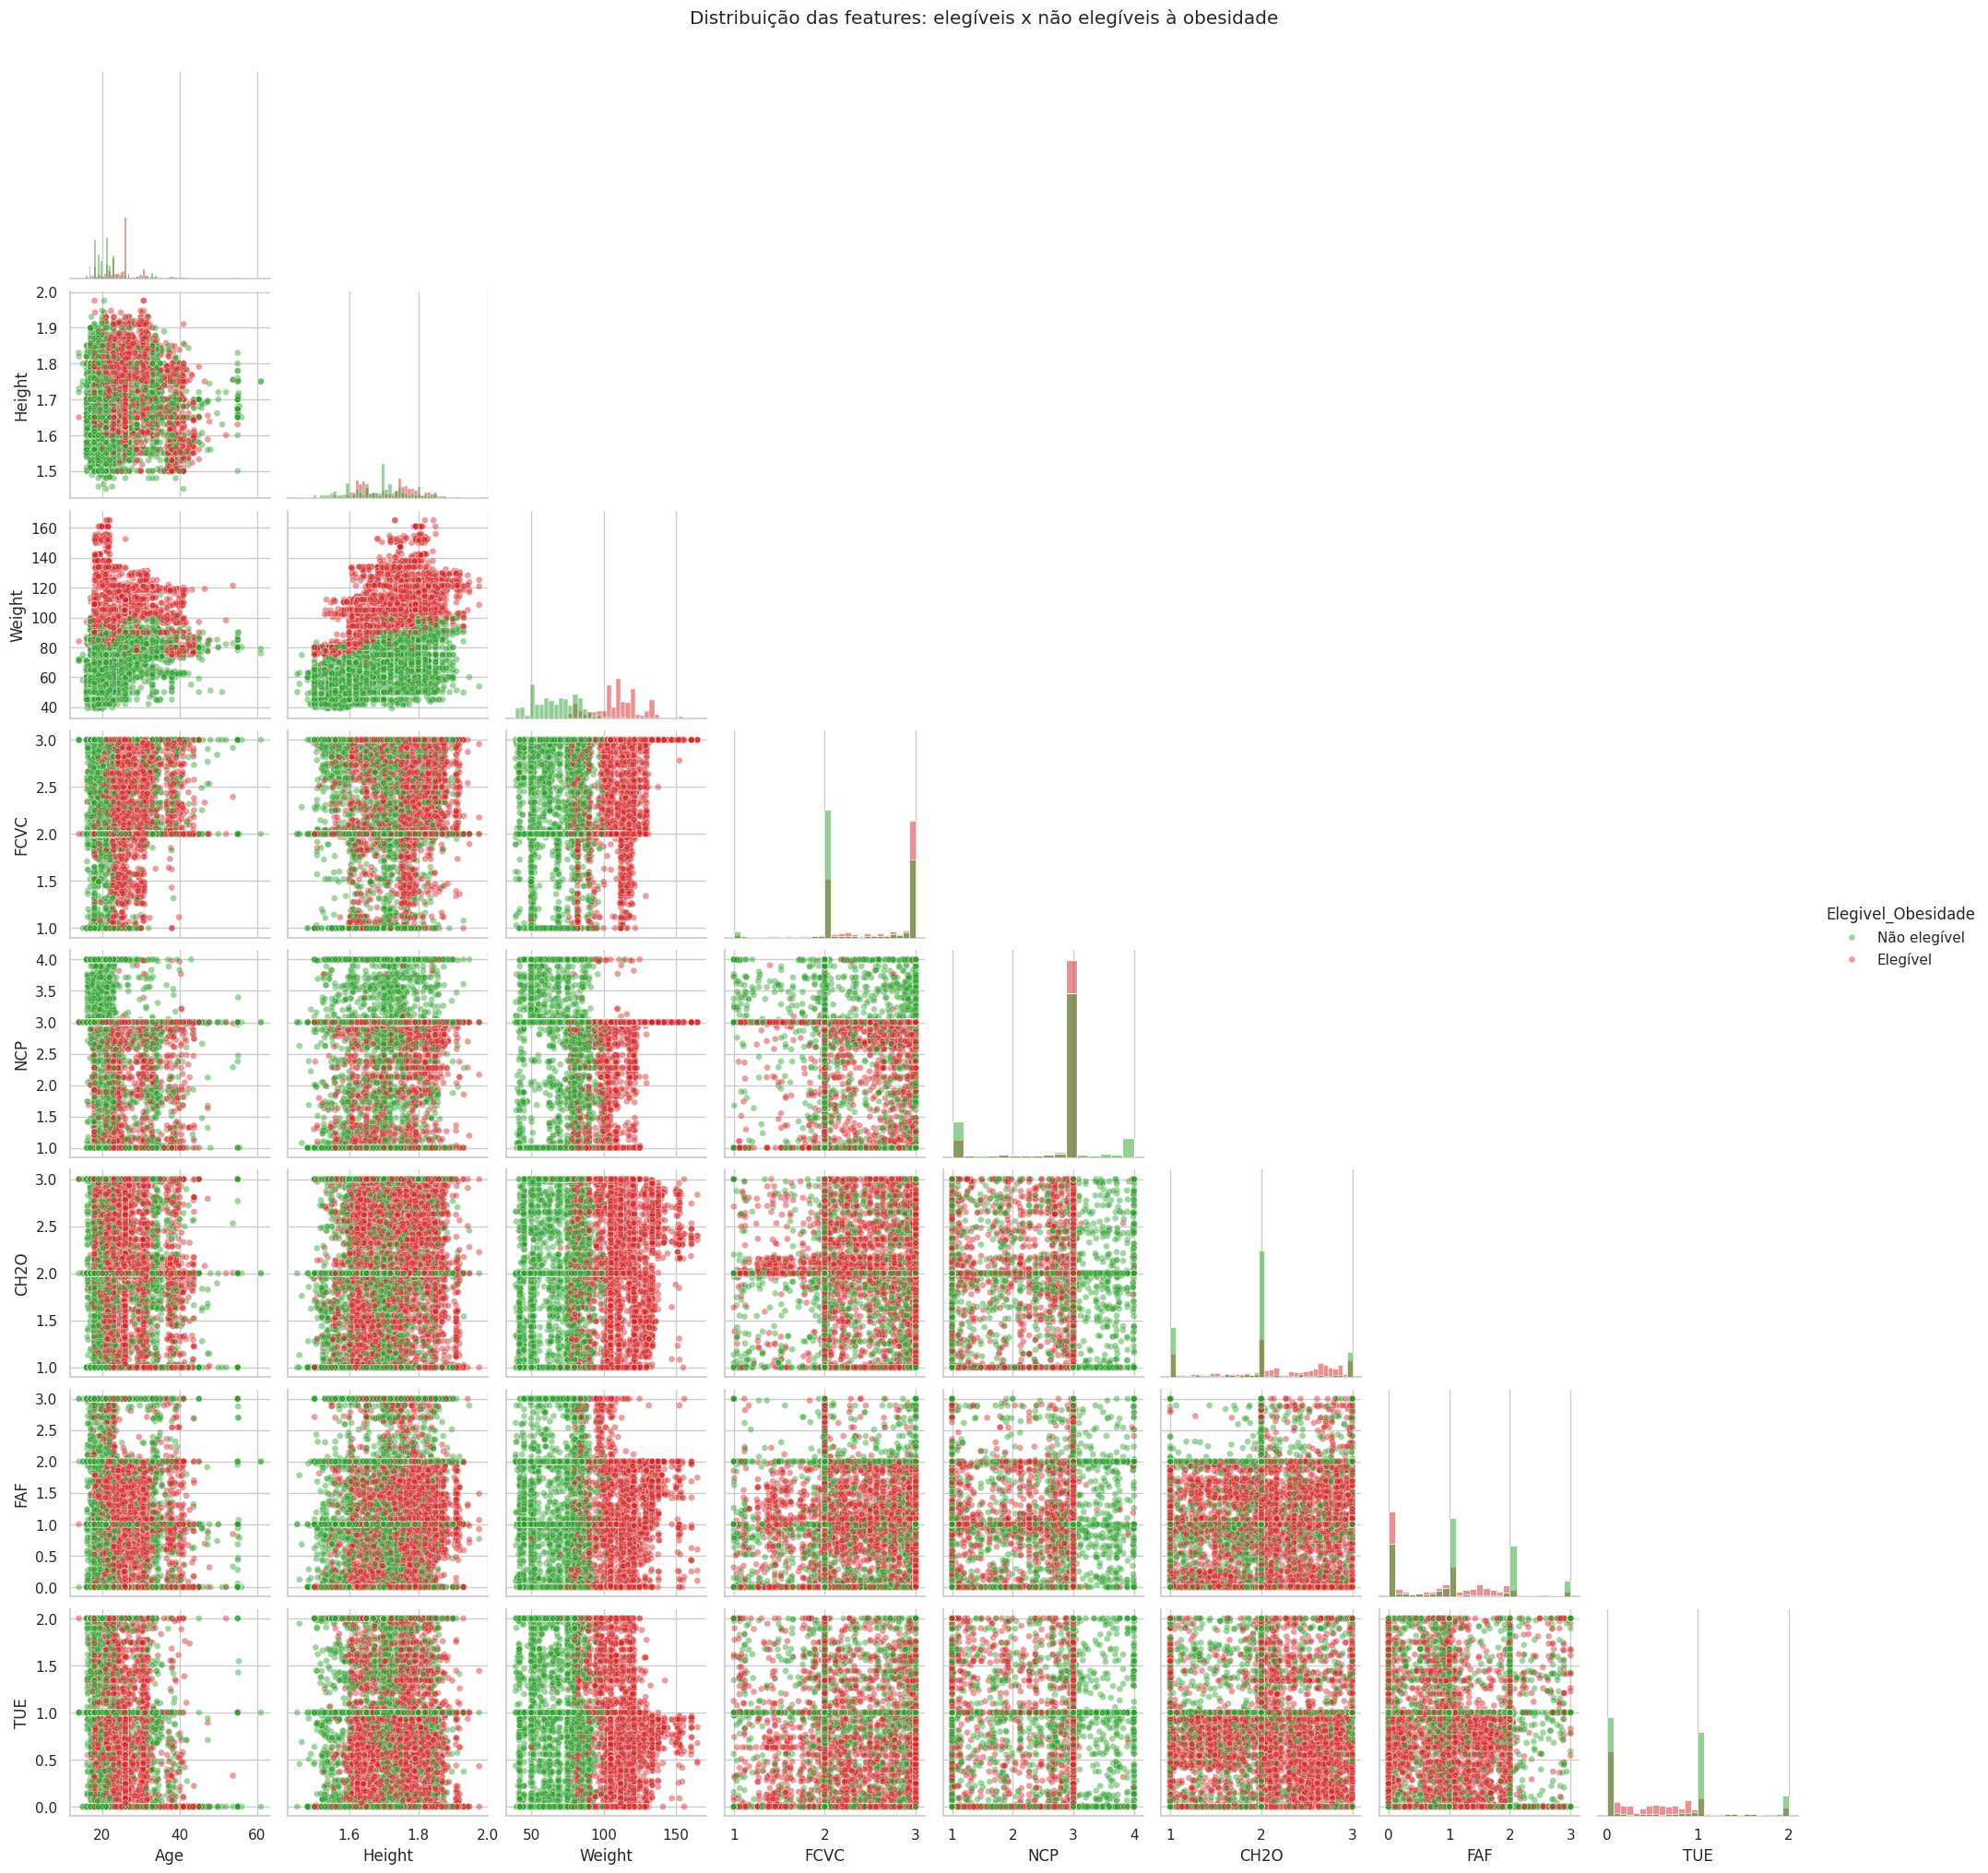

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(
    data=df,
    vars=features_numericas1,
    hue='Elegivel_Obesidade',
    hue_order=['Não elegível', 'Elegível'],
    palette={
        'Não elegível': '#2ca02c',
        'Elegível': '#d62728'
    },
    diag_kind='hist',
    corner=True,
    plot_kws={
        'alpha': 0.45,
        's': 25
    }
)

plt.suptitle(
    'Distribuição das features: elegíveis x não elegíveis à obesidade',
    y=1.02
)

plt.show()


In [41]:
df_amostra = df.sample(
    n=3000,
    random_state=42
)



**Melhorar a Visualizaçã do gráfico**

n=3000 seleciona 3.000 pessoas;

random_state=42 garante que a mesma amostra seja escolhida novamente;

diag_kind='kde' exibe a distribuição de cada variável nas diagonais.

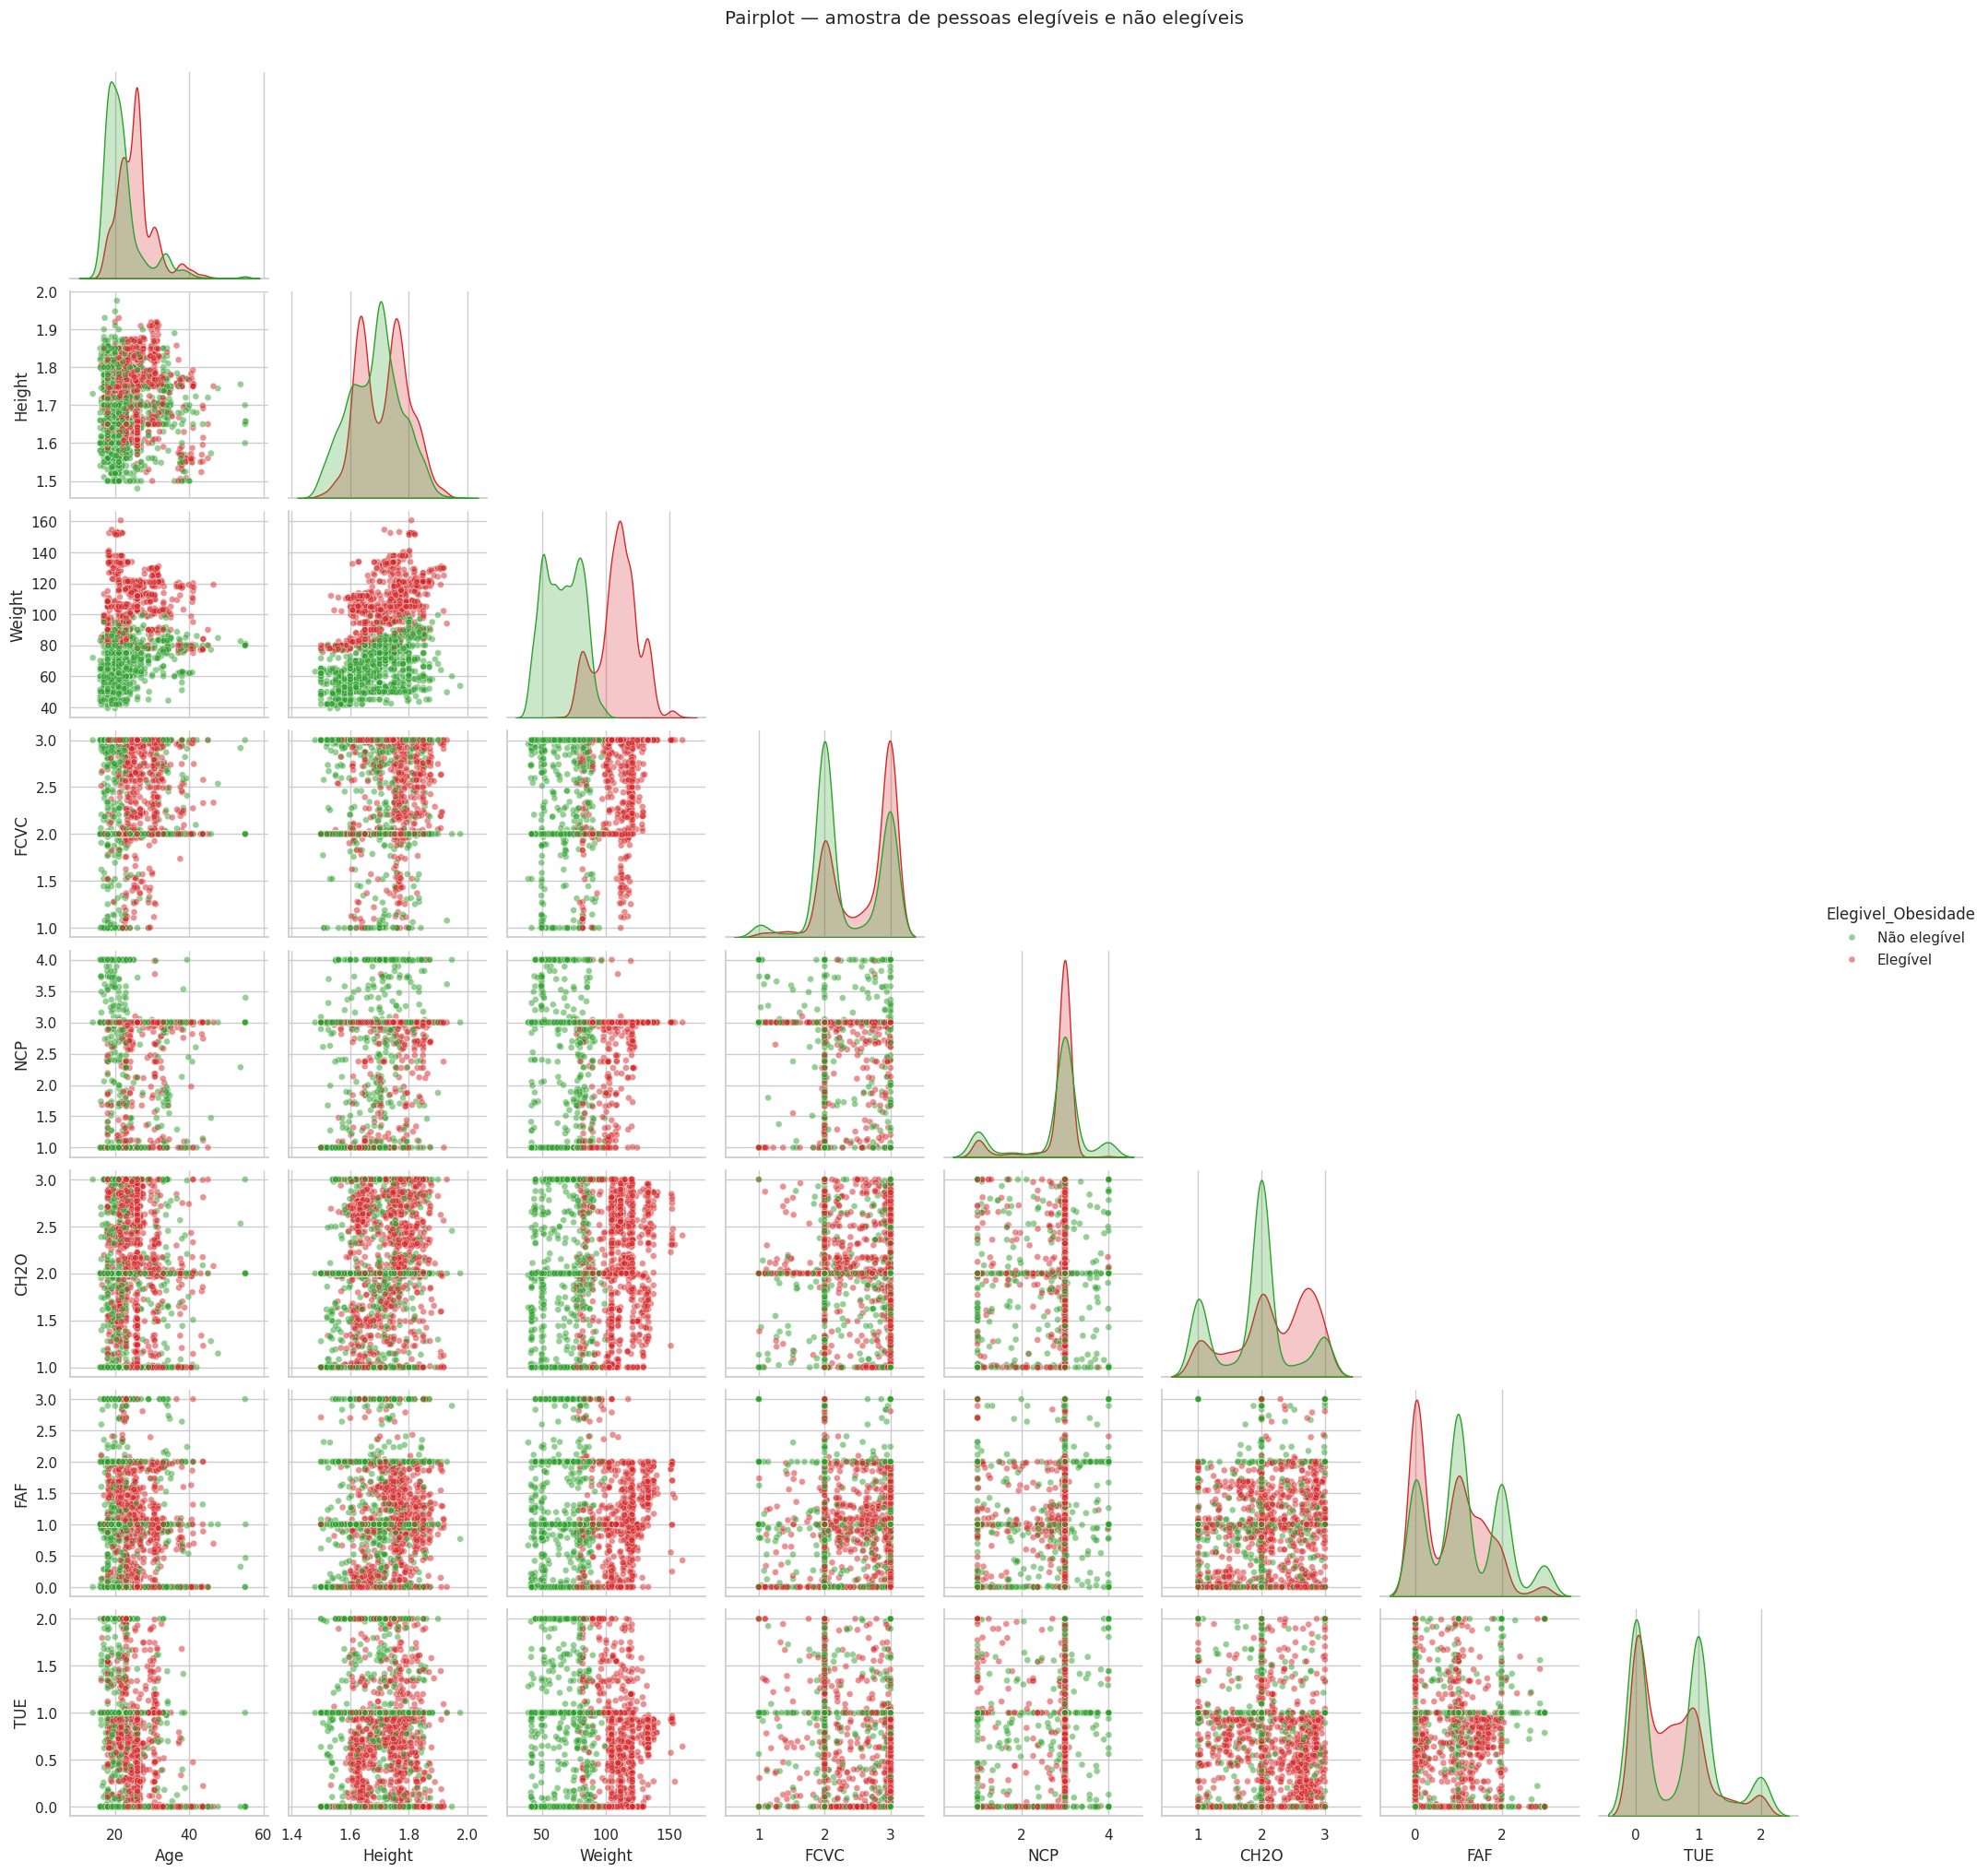

In [42]:
sns.pairplot(
    data=df_amostra,
    vars=features_numericas1,
    hue='Elegivel_Obesidade',
    hue_order=['Não elegível', 'Elegível'],
    palette={
        'Não elegível': '#2ca02c',
        'Elegível': '#d62728'
    },
    diag_kind='kde',
    corner=True,
    plot_kws={
        'alpha': 0.5,
        's': 25
    }
)

plt.suptitle(
    'Pairplot — amostra de pessoas elegíveis e não elegíveis',
    y=1.02
)

plt.show()


**Traduzindo**

Age: idade;

Height: altura;

Weight: peso;

FCVC: frequência de consumo de vegetais;

NCP: quantidade de refeições principais;

CH2O: consumo de água;

FAF: frequência de atividade física;

TUE: tempo de uso de dispositivos eletrônicos.

**Previsoes**

**Incluido IMC**

In [43]:
features_com_imc = [
    'Age',
    'Height',
    'Weight',
    'IMC',
    'FCVC',
    'NCP',
    'CH2O',
    'FAF',
    'TUE'
]


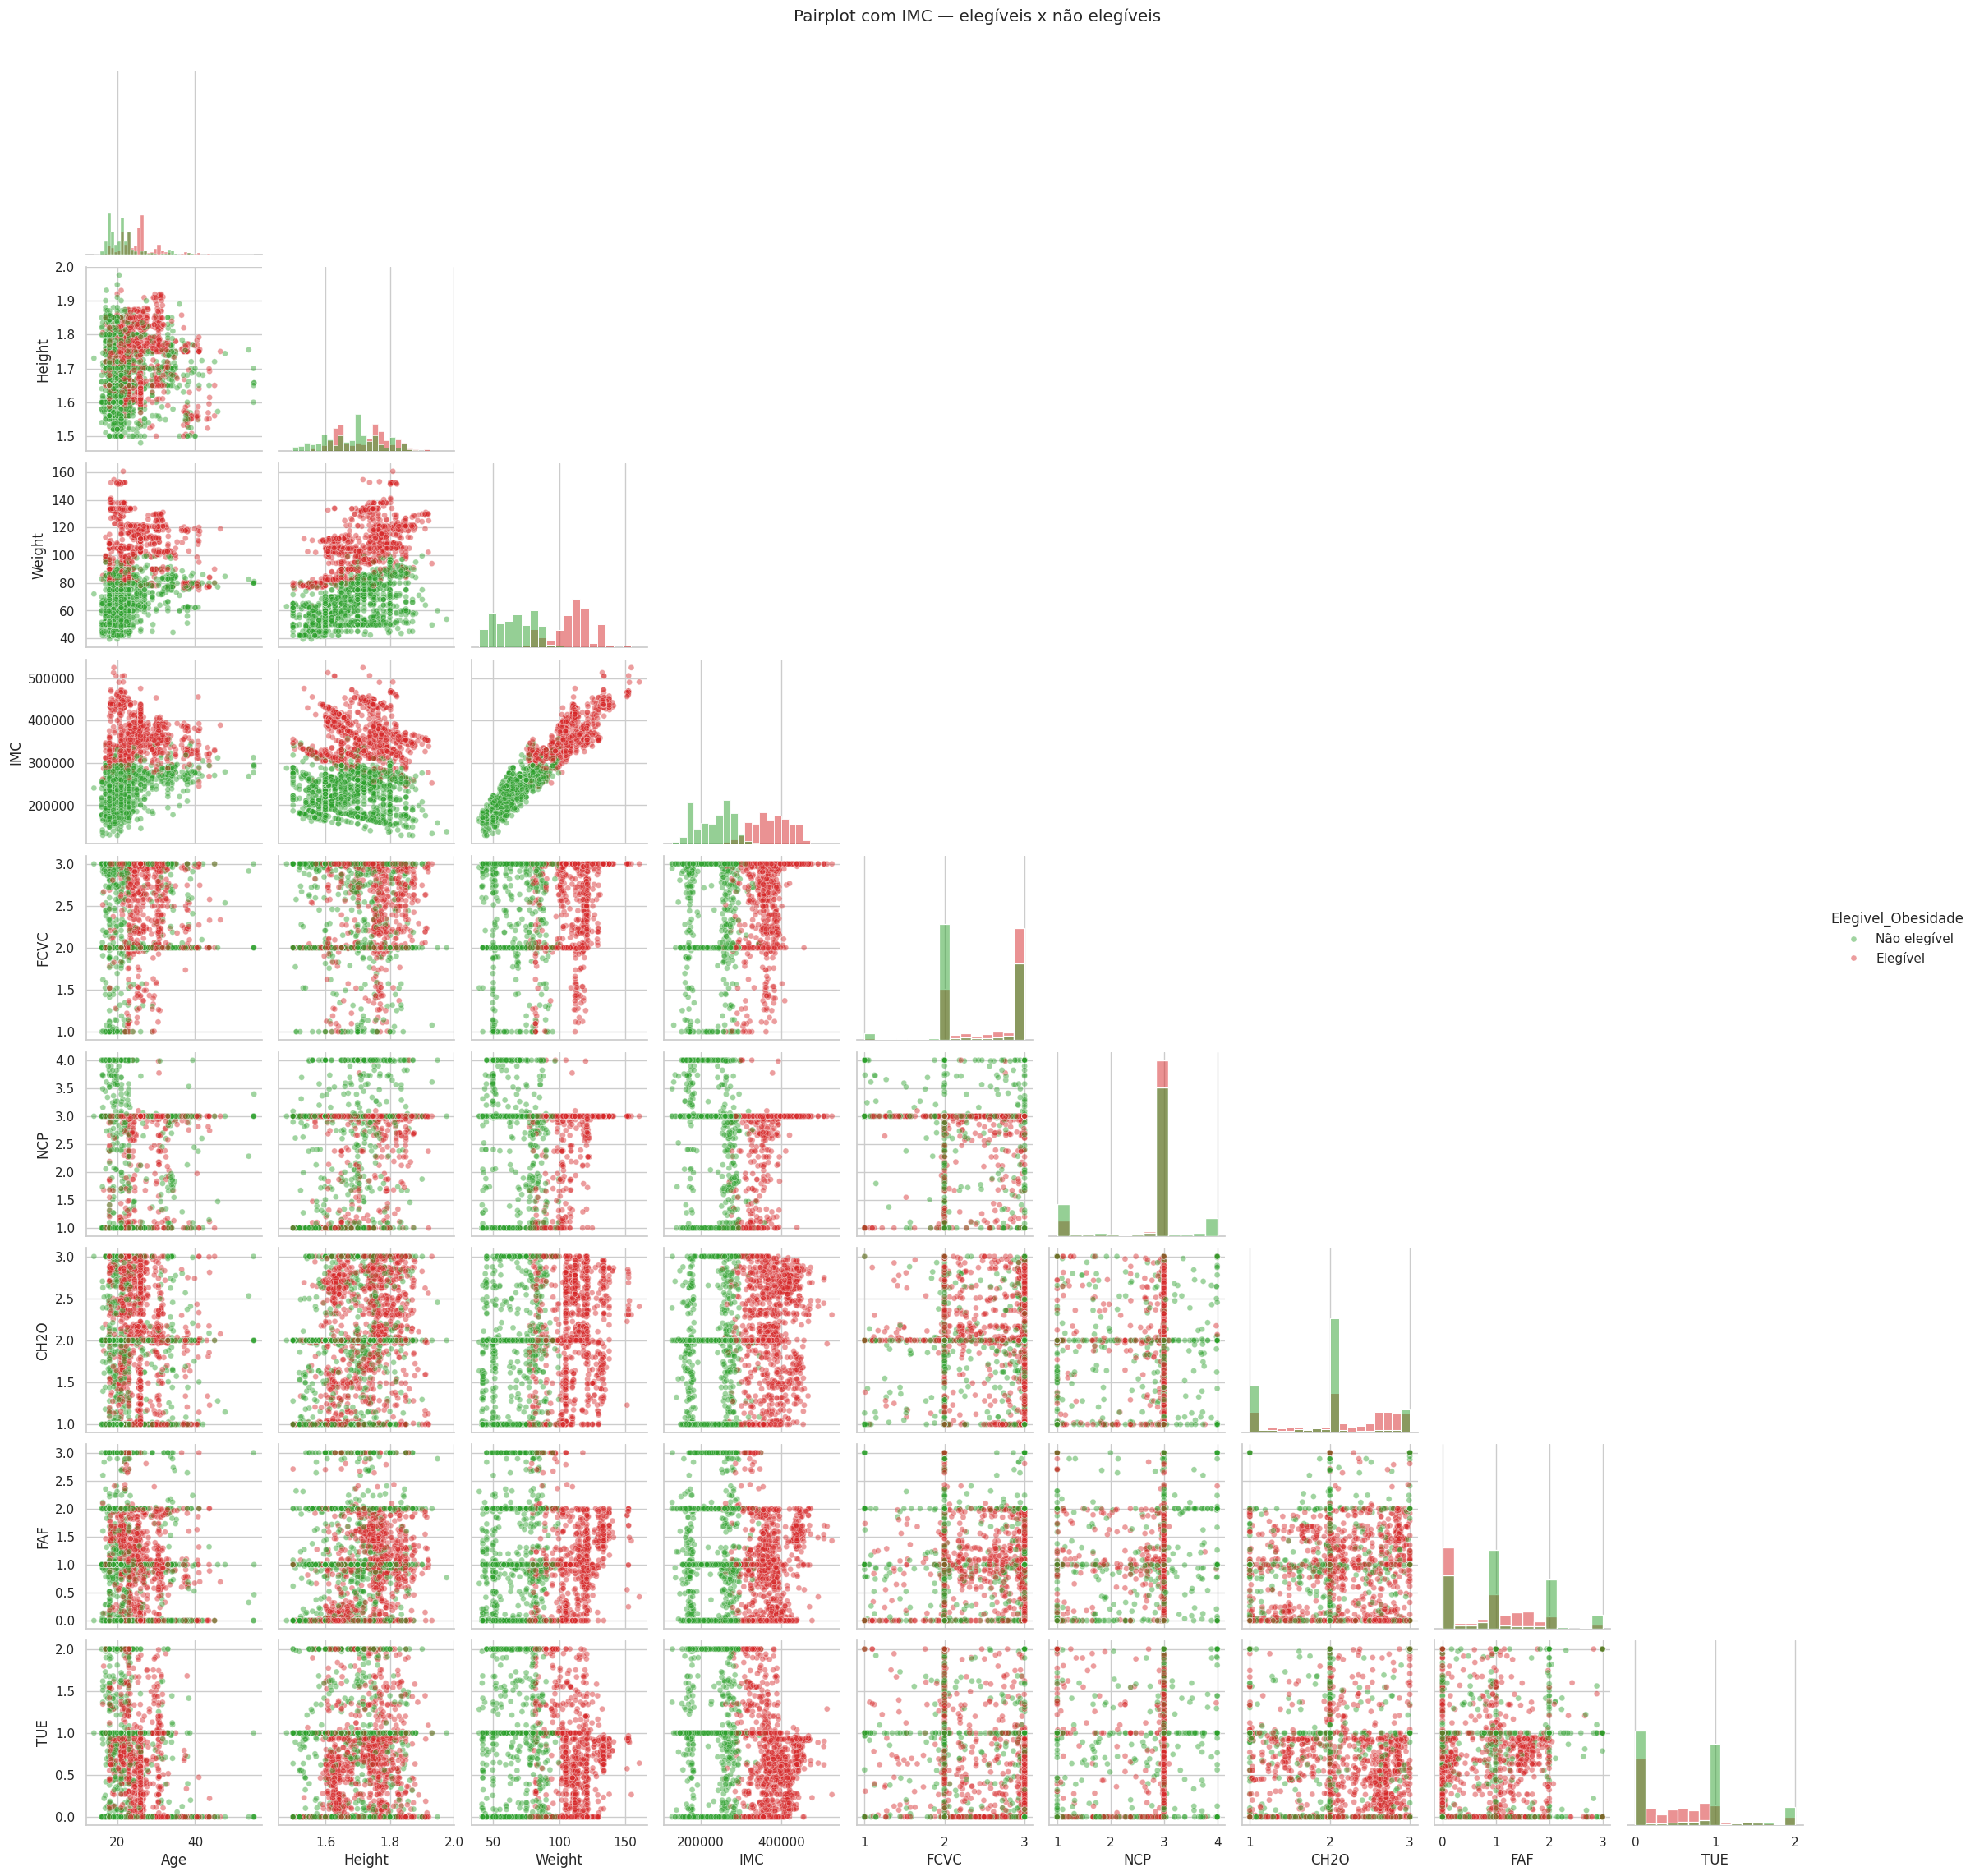

In [44]:
df_amostra = df.sample(
    n=3000,
    random_state=42
)

sns.pairplot(
    data=df_amostra,
    vars=features_com_imc,
    hue='Elegivel_Obesidade',
    hue_order=['Não elegível', 'Elegível'],
    palette={
        'Não elegível': '#2ca02c',
        'Elegível': '#d62728'
    },
    diag_kind='hist',
    corner=True,
    plot_kws={
        'alpha': 0.45,
        's': 25
    }
)

plt.suptitle(
    'Pairplot com IMC — elegíveis x não elegíveis',
    y=1.02
)

plt.show()


**Calcular a acurácia**

Acurácia = previsões corretas / total de previsões

Nosso modelo acertou aproximadamente 83% das classificações.

In [45]:
from sklearn.metrics import accuracy_score

acuracia = accuracy_score(y_teste, y_pred)

print(f'Acurácia do modelo: {acuracia:.4f}')
print(f'Acurácia em porcentagem: {acuracia * 100:.2f}%')


Acurácia do modelo: 0.8316
Acurácia em porcentagem: 83.16%


**Comparando Treinamento com o Teste:**

In [46]:
acuracia_treino = modelo.score(X_treino, y_treino)
acuracia_teste = modelo.score(X_teste, y_teste)

print(f'Acurácia no treinamento: {acuracia_treino:.4f}')
print(f'Acurácia no teste: {acuracia_teste:.4f}')


Acurácia no treinamento: 0.8319
Acurácia no teste: 0.8316


**Relatorio de Classificação**

precision: entre os exemplos classificados como uma categoria, quantos estavam corretos;

recall: entre os exemplos realmente pertencentes a uma categoria, quantos foram encontrados;

f1-score: combinação entre precision e recall;

support: quantidade real de exemplos daquela categoria.

In [47]:
from sklearn.metrics import classification_report

print(classification_report(y_teste, y_pred))


                     precision    recall  f1-score   support

Insufficient_Weight       0.80      0.98      0.88       505
      Normal_Weight       0.86      0.52      0.65       617
     Obesity_Type_I       0.82      0.86      0.84       582
    Obesity_Type_II       0.97      0.93      0.95       650
   Obesity_Type_III       1.00      1.00      1.00       809
 Overweight_Level_I       0.57      0.80      0.67       485
Overweight_Level_II       0.77      0.67      0.72       504

           accuracy                           0.83      4152
          macro avg       0.83      0.82      0.81      4152
       weighted avg       0.85      0.83      0.83      4152



**Matriz de Confusão**

Como Interpretar o grafico abaixo:

As linhas representam as classes reais.

As colunas representam as classes previstas.

A diagonal principal contém os acertos.

Valores fora da diagonal representam erros.

Por exemplo, se muitos indivíduos com uma categoria Overweight forem classificados como Obesity, isso aparecerá fora da diagonal.

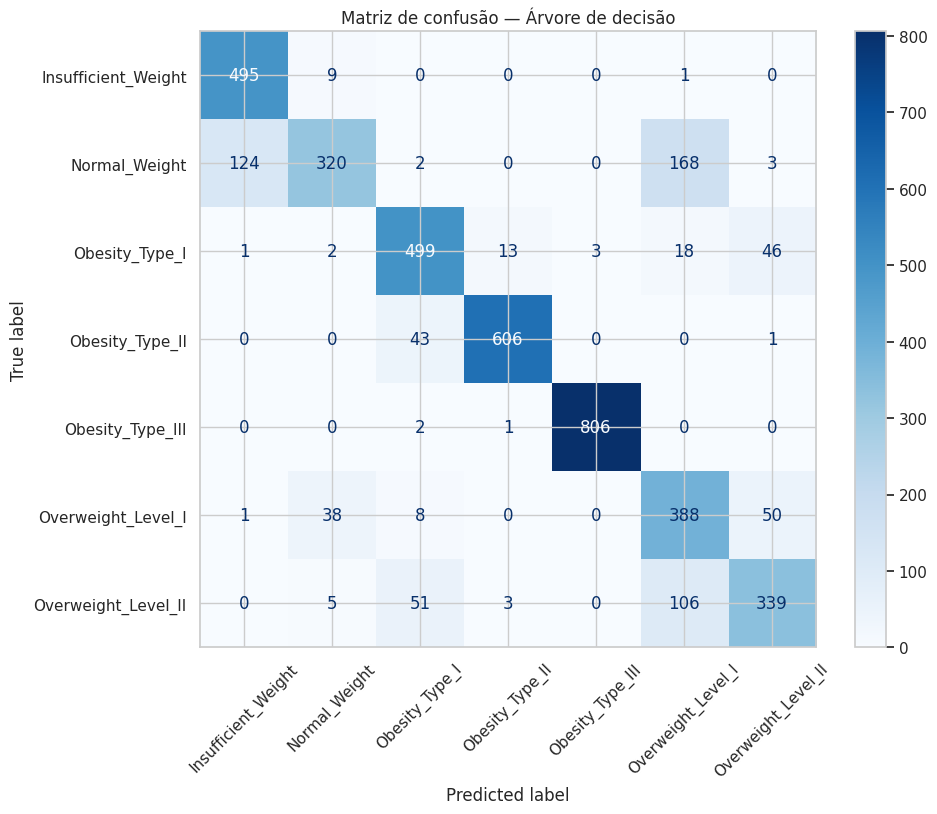

In [48]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matriz = confusion_matrix(
    y_teste,
    y_pred,
    labels=modelo.classes_
)

display_matriz = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=modelo.classes_
)

fig, ax = plt.subplots(figsize=(10, 8))

display_matriz.plot(
    ax=ax,
    cmap='Blues',
    xticks_rotation=45
)

plt.title('Matriz de confusão — Árvore de decisão')
plt.show()


**Avaliando a balanced accuracy**

Como pode haver diferença na quantidade de registros por categoria, é interessante calcular a balanced accuracy

In [49]:
from sklearn.metrics import balanced_accuracy_score

balanced_acuracia = balanced_accuracy_score(y_teste, y_pred)

print(
    f'Balanced accuracy: {balanced_acuracia:.4f}'
)


Balanced accuracy: 0.8225


**Aplicando o Modelo ao DF1 Treino**

In [50]:
df1_modelo = df1.drop(
    columns=['id'],
    errors='ignore'
)


In [51]:
previsoes_df1 = modelo.predict(df1_modelo)


**Aplicando as Previsões ao DF1**

In [52]:
df1['NObeyesdad_Previsto'] = previsoes_df1


**Verificando o Resultado na Base.**


In [53]:
df1.head()


,id,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,IMC,NObeyesdad_Previsto
0,20758,Male,26.899886,1.848294,120.644178,yes,yes,2.938616,3.000000,Sometimes,no,2.825629,no,0.855400,0.000000,Sometimes,Public_Transportation,353154.11,Obesity_Type_II
1,20759,Female,21.000000,1.600000,66.000000,yes,yes,2.000000,1.000000,Sometimes,no,3.000000,no,1.000000,0.000000,Sometimes,Public_Transportation,257812.50,Overweight_Level_I
2,20760,Female,26.000000,1.643355,111.600553,yes,yes,3.000000,3.000000,Sometimes,no,2.621877,no,0.000000,0.250502,Sometimes,Public_Transportation,413241.15,Obesity_Type_III
3,20761,Male,20.979254,1.553127,103.669116,yes,yes,2.000000,2.977909,Sometimes,no,2.786417,no,0.094851,0.000000,Sometimes,Public_Transportation,429769.37,Obesity_Type_I
4,20762,Female,26.000000,1.627396,104.835346,yes,yes,3.000000,3.000000,Sometimes,no,2.653531,no,0.000000,0.741069,Sometimes,Public_Transportation,395841.43,Obesity_Type_III


**Probabilidade de cada previsão**


In [54]:
probabilidades = modelo.predict_proba(df1_modelo)
classes = modelo.classes_

print(classes)


['Insufficient_Weight' 'Normal_Weight' 'Obesity_Type_I' 'Obesity_Type_II'
 'Obesity_Type_III' 'Overweight_Level_I' 'Overweight_Level_II']


In [55]:
df1['Probabilidade'] = probabilidades.max(axis=1)


In [56]:
df1[
    ['NObeyesdad_Previsto', 'Probabilidade']
].head()


,NObeyesdad_Previsto,Probabilidade
0,Obesity_Type_II,0.993781
1,Overweight_Level_I,0.484600
2,Obesity_Type_III,0.999594
3,Obesity_Type_I,0.978972
4,Obesity_Type_III,0.993386


**INICIANDO IMPLEMENTAÇÃO DO RANDOM FOREST**

In [57]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay)

**Criando Modelo Random Forest**

In [58]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    criterion='entropy',
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)



Criar o Pipe

In [59]:
modelo_rf = Pipeline(
    steps=[
        ('preprocessamento', preprocessamento),
        ('random_forest', random_forest)
    ]
)


**Treina Modelo**

In [60]:
modelo_rf.fit(X_treino, y_treino)


Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('categoricas',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender',
                                                   'family_history_with_overweight',
                                                   'FAVC', 'CAEC', 'SMOKE',
                                                   'SCC', 'CALC', 'MTRANS']),
                                                 ('numericas', 'passthrough',
                                                  ['Age', 'Height', 'Weight',
                                                   'FCVC', 'NCP', 'CH2O', 'FAF',
                                                   'TUE'])])),
                ('random_forest',
                 RandomForestClassifier(criterion='entropy', max_depth=12,
                                        min_samples_leaf=5,
                                        min_samples_split=10, n_estimators=200,
                                        n_jobs=-1, random_state=42))])

**Aplica Modelo**

y_teste: valores reais;

y_pred_rf: valores previstos pela Random Forest.

In [61]:
y_pred_rf = modelo_rf.predict(X_teste)


**Calcular Acuracia**

In [62]:
acuracia_treino_rf = modelo_rf.score(
    X_treino,
    y_treino
)

acuracia_teste_rf = accuracy_score(
    y_teste,
    y_pred_rf
)

balanced_acuracia_rf = balanced_accuracy_score(
    y_teste,
    y_pred_rf
)

print(f'Acurácia no treinamento: {acuracia_treino_rf:.4f}')
print(f'Acurácia no teste: {acuracia_teste_rf:.4f}')
print(f'Balanced accuracy: {balanced_acuracia_rf:.4f}')


Acurácia no treinamento: 0.9214
Acurácia no teste: 0.8902
Balanced accuracy: 0.8773


**Relatorio de Classificação RF**

In [63]:
print(
    classification_report(
        y_teste,
        y_pred_rf
    )
)


                     precision    recall  f1-score   support

Insufficient_Weight       0.92      0.93      0.93       505
      Normal_Weight       0.82      0.87      0.84       617
     Obesity_Type_I       0.87      0.89      0.88       582
    Obesity_Type_II       0.96      0.97      0.96       650
   Obesity_Type_III       1.00      1.00      1.00       809
 Overweight_Level_I       0.82      0.67      0.74       485
Overweight_Level_II       0.78      0.81      0.79       504

           accuracy                           0.89      4152
          macro avg       0.88      0.88      0.88      4152
       weighted avg       0.89      0.89      0.89      4152



**Mariz de Confusão RF**

valores na diagonal representam acertos;

valores fora da diagonal representam erros;

cada linha representa a classe real;

cada coluna representa a classe prevista.

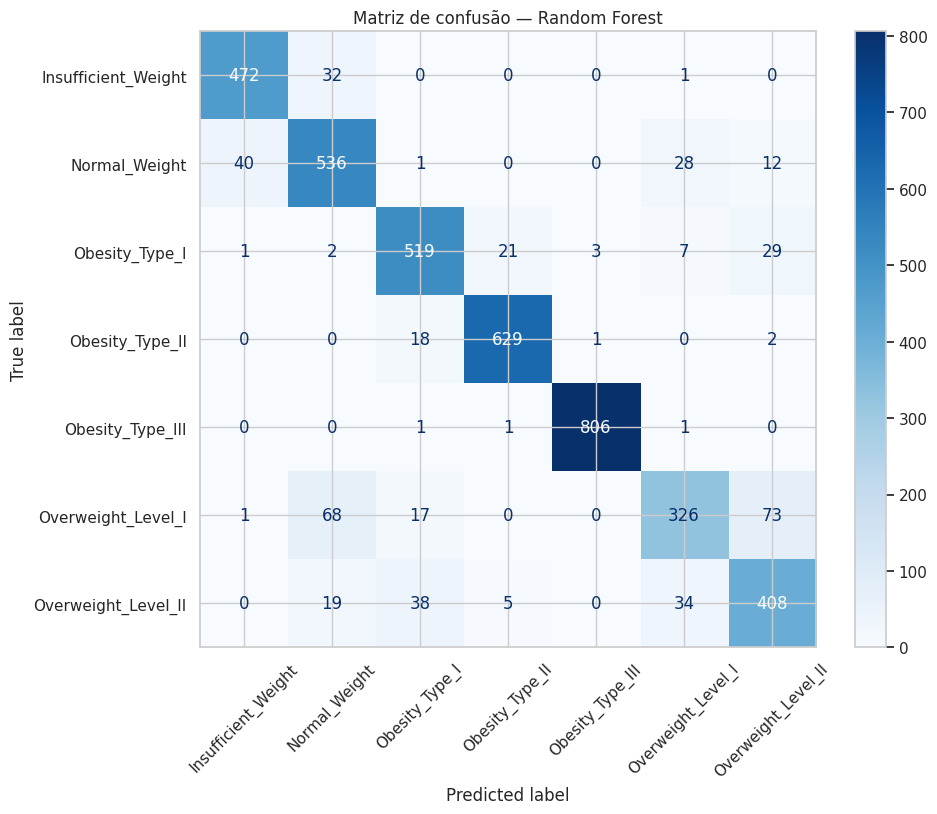

In [64]:
matriz_rf = confusion_matrix(
    y_teste,
    y_pred_rf,
    labels=modelo_rf.classes_
)

display_rf = ConfusionMatrixDisplay(
    confusion_matrix=matriz_rf,
    display_labels=modelo_rf.classes_
)

fig, ax = plt.subplots(figsize=(10, 8))

display_rf.plot(
    ax=ax,
    cmap='Blues',
    xticks_rotation=45
)

plt.title('Matriz de confusão — Random Forest')
plt.show()


**Aplicar RF no DF1**

In [65]:
# Colunas utilizadas no treinamento
colunas_necessarias = [
    'Gender',
    'Age',
    'Height',
    'Weight',
    'family_history_with_overweight',
    'FAVC',
    'FCVC',
    'NCP',
    'CAEC',
    'SMOKE',
    'CH2O',
    'SCC',
    'FAF',
    'TUE',
    'CALC',
    'MTRANS'
]

# Conferir colunas ausentes
colunas_faltantes = [
    coluna for coluna in colunas_necessarias
    if coluna not in df1.columns
]

if colunas_faltantes:
    raise ValueError(
        f'Colunas faltantes no df1: {colunas_faltantes}'
    )

# Selecionar somente as colunas usadas pelo modelo
df1_modelo = df1[colunas_necessarias]

# Gerar previsões
previsoes_df1 = modelo_rf.predict(df1_modelo)

# Criar cópia e adicionar as previsões
df1_resultado = df1.copy()

df1_resultado['NObeyesdad_Previsto'] = previsoes_df1

df1_resultado.head()


,id,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,IMC,NObeyesdad_Previsto,Probabilidade
0,20758,Male,26.899886,1.848294,120.644178,yes,yes,2.938616,3.000000,Sometimes,no,2.825629,no,0.855400,0.000000,Sometimes,Public_Transportation,353154.11,Obesity_Type_II,0.993781
1,20759,Female,21.000000,1.600000,66.000000,yes,yes,2.000000,1.000000,Sometimes,no,3.000000,no,1.000000,0.000000,Sometimes,Public_Transportation,257812.50,Overweight_Level_I,0.484600
2,20760,Female,26.000000,1.643355,111.600553,yes,yes,3.000000,3.000000,Sometimes,no,2.621877,no,0.000000,0.250502,Sometimes,Public_Transportation,413241.15,Obesity_Type_III,0.999594
3,20761,Male,20.979254,1.553127,103.669116,yes,yes,2.000000,2.977909,Sometimes,no,2.786417,no,0.094851,0.000000,Sometimes,Public_Transportation,429769.37,Obesity_Type_I,0.978972
4,20762,Female,26.000000,1.627396,104.835346,yes,yes,3.000000,3.000000,Sometimes,no,2.653531,no,0.000000,0.741069,Sometimes,Public_Transportation,395841.43,Obesity_Type_III,0.993386


**Comparação de Resultados**

,Modelo,Acurácia no treinamento,Acurácia no teste,Balanced Accuracy,Precisão ponderada,Recall ponderado,F1-score ponderado
0,Árvore de Decisão,83.19%,83.16%,82.25%,84.64%,83.16%,82.9%
1,Random Forest,92.14%,89.02%,87.73%,88.98%,89.02%,88.89%



Melhor modelo pela acurácia de teste: Random Forest
Acurácia obtida: 89.02%


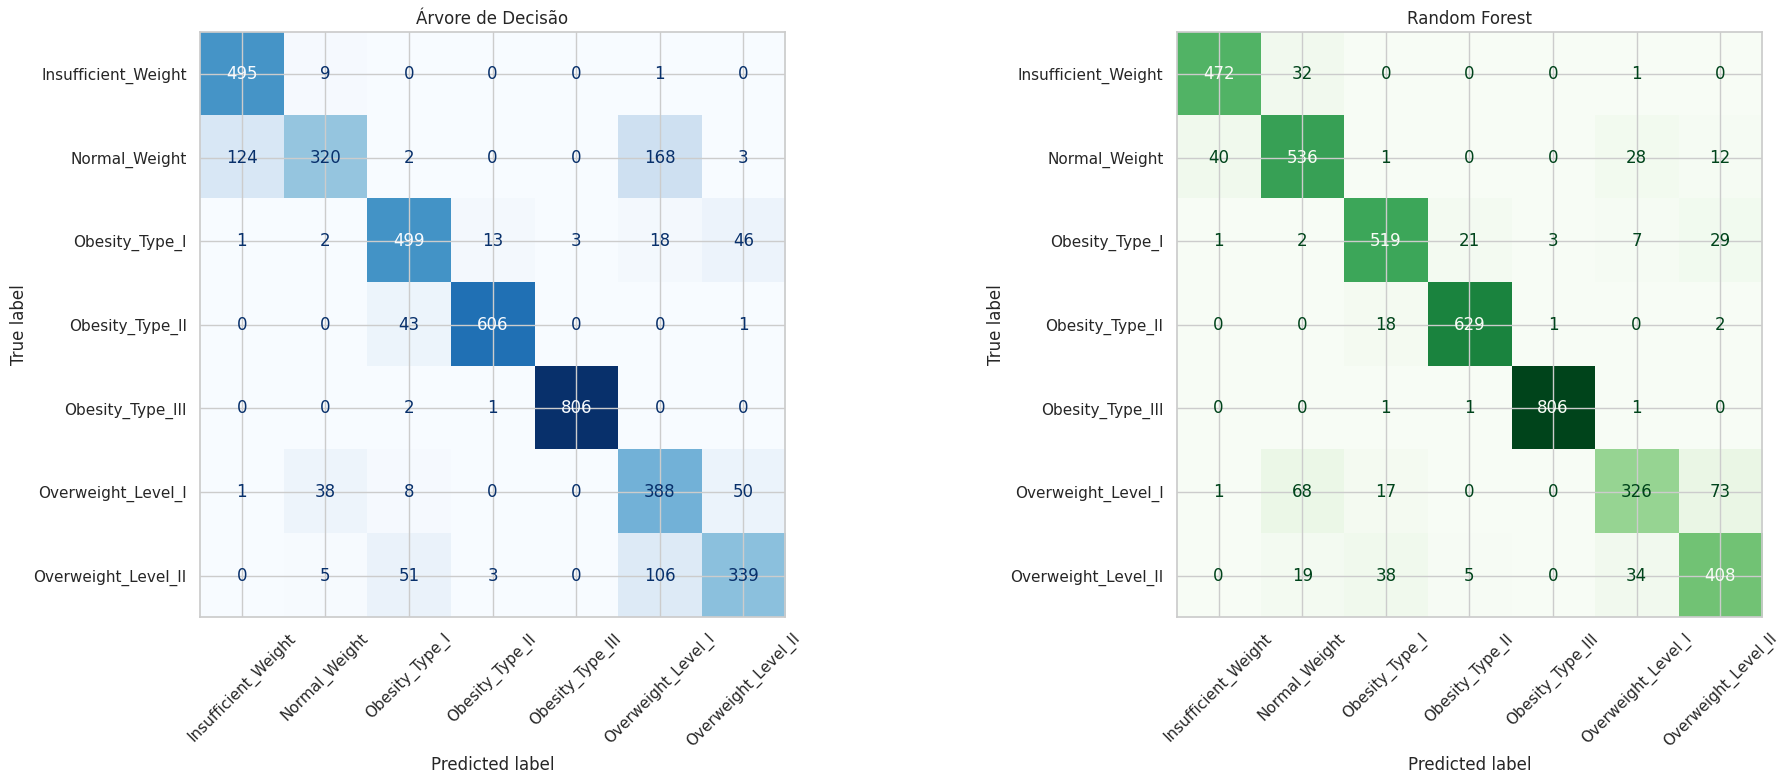

In [66]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ==================================================
# 1. Fazer previsões nos mesmos dados de teste
# ==================================================

y_pred_arvore = modelo.predict(X_teste)
y_pred_rf = modelo_rf.predict(X_teste)

# ==================================================
# 2. Criar tabela de métricas
# ==================================================

df_comparacao = pd.DataFrame({
    'Modelo': [
        'Árvore de Decisão',
        'Random Forest'
    ],

    'Acurácia no treinamento': [
        modelo.score(X_treino, y_treino),
        modelo_rf.score(X_treino, y_treino)
    ],

    'Acurácia no teste': [
        accuracy_score(y_teste, y_pred_arvore),
        accuracy_score(y_teste, y_pred_rf)
    ],

    'Balanced Accuracy': [
        balanced_accuracy_score(y_teste, y_pred_arvore),
        balanced_accuracy_score(y_teste, y_pred_rf)
    ],

    'Precisão ponderada': [
        precision_score(
            y_teste,
            y_pred_arvore,
            average='weighted',
            zero_division=0
        ),
        precision_score(
            y_teste,
            y_pred_rf,
            average='weighted',
            zero_division=0
        )
    ],

    'Recall ponderado': [
        recall_score(
            y_teste,
            y_pred_arvore,
            average='weighted',
            zero_division=0
        ),
        recall_score(
            y_teste,
            y_pred_rf,
            average='weighted',
            zero_division=0
        )
    ],

    'F1-score ponderado': [
        f1_score(
            y_teste,
            y_pred_arvore,
            average='weighted',
            zero_division=0
        ),
        f1_score(
            y_teste,
            y_pred_rf,
            average='weighted',
            zero_division=0
        )
    ]
})

# ==================================================
# 3. Exibir tabela formatada
# ==================================================

df_formatada = df_comparacao.copy()

colunas_metricas = [
    'Acurácia no treinamento',
    'Acurácia no teste',
    'Balanced Accuracy',
    'Precisão ponderada',
    'Recall ponderado',
    'F1-score ponderado'
]

for coluna in colunas_metricas:
    df_formatada[coluna] = (
        df_formatada[coluna] * 100
    ).round(2).astype(str) + '%'

display(df_formatada)

# ==================================================
# 4. Identificar o melhor modelo
# ==================================================

indice_melhor = df_comparacao[
    'Acurácia no teste'
].idxmax()

melhor_modelo = df_comparacao.loc[
    indice_melhor,
    'Modelo'
]

melhor_acuracia = df_comparacao.loc[
    indice_melhor,
    'Acurácia no teste'
]

print(
    f'\nMelhor modelo pela acurácia de teste: '
    f'{melhor_modelo}'
)

print(
    f'Acurácia obtida: {melhor_acuracia:.2%}'
)

# ==================================================
# 5. Matrizes de confusão
# ==================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(20, 8)
)

# Árvore
matriz_arvore = confusion_matrix(
    y_teste,
    y_pred_arvore,
    labels=modelo.classes_
)

disp_arvore = ConfusionMatrixDisplay(
    confusion_matrix=matriz_arvore,
    display_labels=modelo.classes_
)

disp_arvore.plot(
    ax=axes[0],
    cmap='Blues',
    xticks_rotation=45,
    colorbar=False
)

axes[0].set_title('Árvore de Decisão')

# Random Forest
matriz_rf = confusion_matrix(
    y_teste,
    y_pred_rf,
    labels=modelo_rf.classes_
)

disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=matriz_rf,
    display_labels=modelo_rf.classes_
)

disp_rf.plot(
    ax=axes[1],
    cmap='Greens',
    xticks_rotation=45,
    colorbar=False
)

axes[1].set_title('Random Forest')

plt.tight_layout()
plt.show()


**Interpretando a Matriz de Confusão:**

A diagonal principal representa os acertos;

Os valores fora da diagonal representam erros;

Quanto mais concentrados os valores na diagonal, melhor o modelo;

Se uma classe é frequentemente confundida com outra, isso aparecerá
nas células fora da diagonal;

**Explicando o Resultado da Comparação:**

A Random Forest apresentou desempenho superior na base de teste porque combina várias árvores de decisão, em vez de depender de uma única estrutura de regras. Cada árvore aprende padrões diferentes dos dados e, ao combinar essas previsões, a floresta reduz a dependência de uma única divisão e tende a generalizar melhor para novos indivíduos.

**Exporta arquivo CSVs**

In [68]:
# Selecionar as colunas usadas no treinamento
df1_modelo = df1[colunas_necessarias]

# Fazer as previsões
pred_arvore = modelo.predict(df1_modelo)
pred_rf = modelo_rf.predict(df1_modelo)

# Criar e exportar o resultado da árvore
pd.DataFrame({
    'id': df1['id'],
    'NObeyesdad_Previsto': pred_arvore
}).to_csv(
    'previsoes_arvore_decisao.csv',
    index=False
)

# Criar e exportar o resultado da Random Forest
pd.DataFrame({
    'id': df1['id'],
    'NObeyesdad_Previsto': pred_rf
}).to_csv(
    'previsoes_random_forest.csv',
    index=False
)
